<a href="https://colab.research.google.com/github/JazielAyala/Algoritmos26b/blob/main/Pract.05_Divide_y_VencerAs_MNIST/ActividadColab.ipynb." target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Cargando dataset desde: mnist_train.csv...
Extrayendo muestra aleatoria de 5000 elementos...

Iniciando transformacion t-SNE (Conjunto Global)...


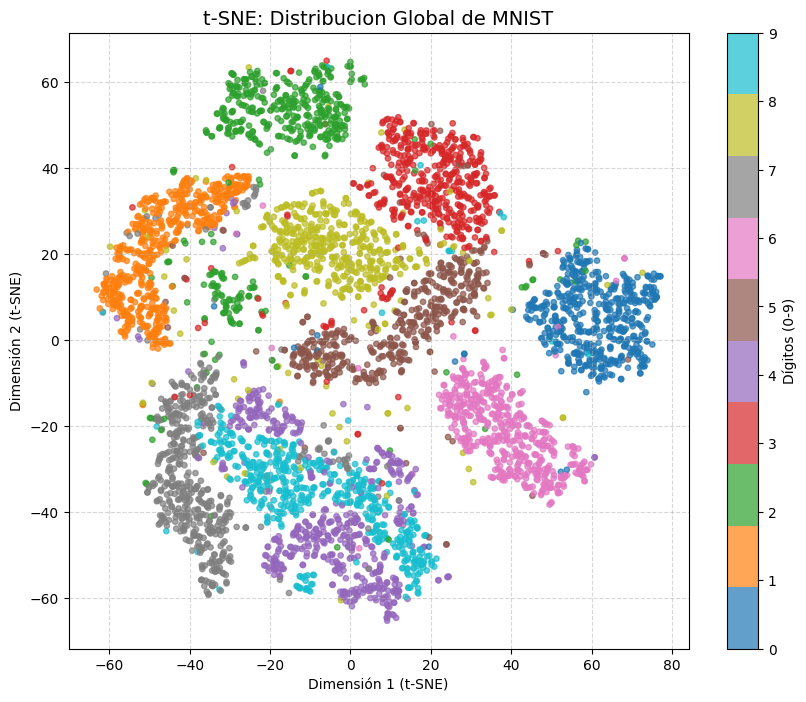


Filtrando la base de datos para aislar el clúster del dígito 7...
Instancias del dígito 7 encontradas en la muestra: 520
Iniciando transformacion t-SNE (Dígito 7 aislado)...


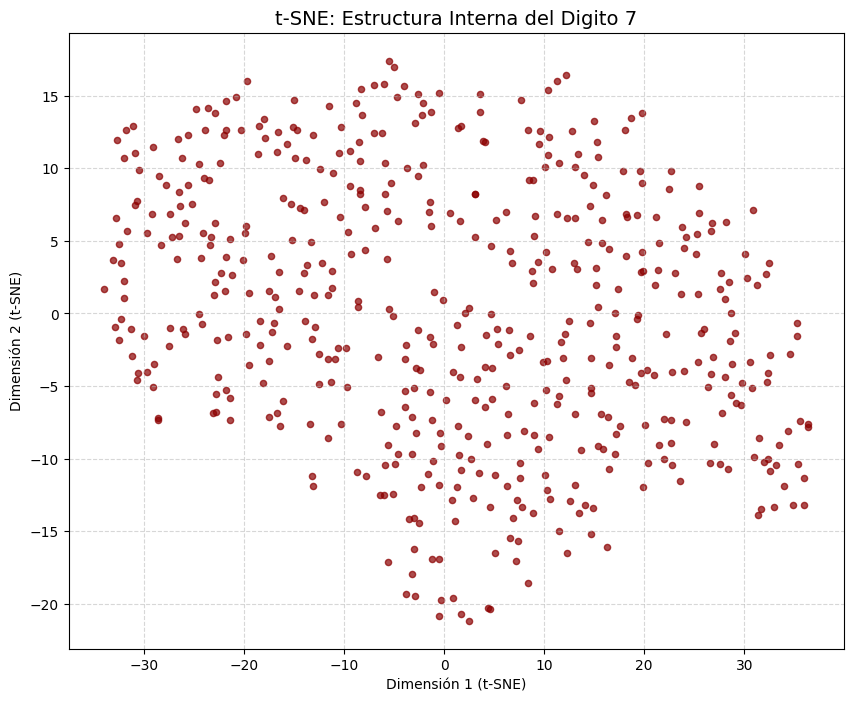

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE

def cargar_datos(ruta_archivo, tamanoMuestra=None):
    print(f"Cargando dataset desde: {ruta_archivo}...")
    try:
        df = pd.read_csv(ruta_archivo)
    except FileNotFoundError:
        print("No se encontro el archivo.")
        return None, None
    yCompleto = df['label']
    xCompleto = df.drop('label', axis=1)

    # Submuestreo para analisis de rendimiento
    if tamanoMuestra and tamanoMuestra < len(df):
        print(f"Extrayendo muestra aleatoria de {tamanoMuestra} elementos...")
        X = xCompleto.sample(n=tamanoMuestra, random_state=42)
        y = yCompleto.loc[X.index]
    else:
        X, y = xCompleto, yCompleto

    return X, y

def graficar_espacio(XTransformado, y, titulo, esGlobal=True):

    plt.figure(figsize=(10, 8))

    if esGlobal:
        # Grafico con mapa de colores categorico (0-9)
        scatter = plt.scatter(XTransformado[:, 0], XTransformado[:, 1],
                              c=y, cmap='tab10', alpha=0.7, s=15)
        plt.colorbar(scatter, label='Dígitos (0-9)')
    else:
        # Grafico de un solo color para analisis aislado
        plt.scatter(XTransformado[:, 0], XTransformado[:, 1],
                    color='#8B0000', alpha=0.7, s=20)

    plt.title(titulo, fontsize=14)
    plt.xlabel('Dimensión 1 (t-SNE)')
    plt.ylabel('Dimensión 2 (t-SNE)')
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.show()

def main():
    ruta_csv = 'mnist_train.csv'

    X, y = cargar_datos(ruta_csv, tamanoMuestra=5000)
    if X is None: return

    print("\nIniciando transformacion t-SNE (Conjunto Global)...")
    tsne_global = TSNE(n_components=2, random_state=42, perplexity=30.0)

    X_tsne_global = tsne_global.fit_transform(X)

    graficar_espacio(X_tsne_global, y, "t-SNE: Distribucion Global de MNIST", esGlobal=True)

    # 3. Analisis Aislado (Digito 7)
    print("\nFiltrando la base de datos para aislar el clúster del dígito 7...")
    # Indexacion booleana para extraer solo los 7s
    X_7 = X[y == 7]

    print(f"Instancias del dígito 7 encontradas en la muestra: {len(X_7)}")
    print("Iniciando transformacion t-SNE (Dígito 7 aislado)...")

    tsne_7 = TSNE(n_components=2, random_state=42, perplexity=30.0)

    X_tsne_7 = tsne_7.fit_transform(X_7)

    graficar_espacio(X_tsne_7, None, "t-SNE: Estructura Interna del Digito 7", esGlobal=False)

if __name__ == "__main__":
    main()